In [1]:
import pandas as pd

employees = pd.read_csv("../../data/synthetic/employees.csv")
access = pd.read_csv("../../data/synthetic/access_records.csv")
logins = pd.read_csv("../../data/synthetic/login_logs.csv")
findings = pd.read_csv("../../data/synthetic/audit_findings.csv")
controls = pd.read_csv("../../data/synthetic/compliance_controls.csv")
historical = pd.read_csv("../../data/synthetic/historical_audits.csv")

print("Employees:", employees.shape)
print("Access records:", access.shape)
print("Login logs:", logins.shape)
print("Findings:", findings.shape)

Employees: (250, 8)
Access records: (500, 10)
Login logs: (20164, 9)
Findings: (220, 8)


In [2]:
for name, df in [("employees", employees), ("access", access), ("logins", logins), ("findings", findings)]:
    print(f"--- {name} ---")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

--- employees ---
Missing values: 9
Duplicate rows: 0
--- access ---
Missing values: 0
Duplicate rows: 0
--- logins ---
Missing values: 21
Duplicate rows: 0
--- findings ---
Missing values: 39
Duplicate rows: 0


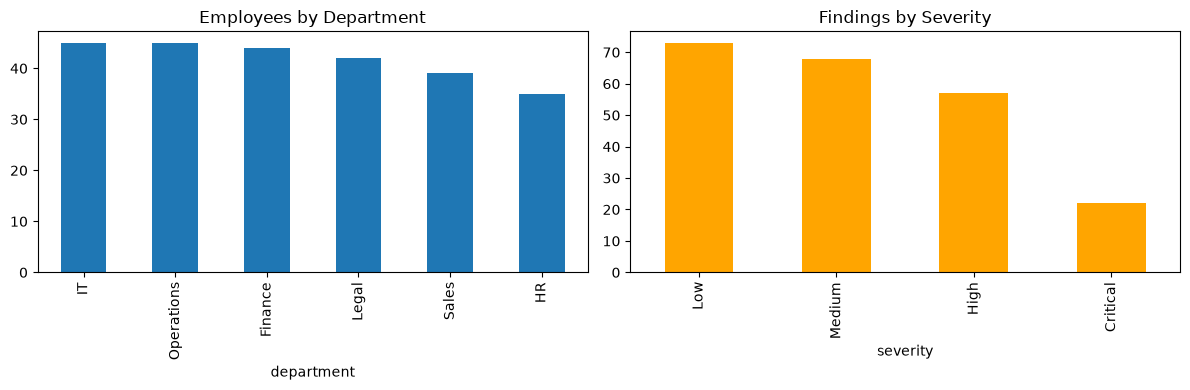

In [3]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
employees["department"].value_counts().plot(kind="bar", ax=axes[0], title="Employees by Department")
findings["severity"].value_counts().plot(kind="bar", ax=axes[1], title="Findings by Severity", color="orange")
plt.tight_layout()
plt.show()

In [4]:
mfa_pct = access["mfa_enabled"].mean() * 100
print(f"Overall MFA adoption: {mfa_pct:.1f}%")

privileged = access[access["privilege_level"].isin(["Elevated", "Admin"])]
no_mfa = privileged[privileged["mfa_enabled"] == False]
print(f"Privileged accounts WITHOUT MFA: {len(no_mfa)} out of {len(privileged)}")

Overall MFA adoption: 97.2%
Privileged accounts WITHOUT MFA: 14 out of 149


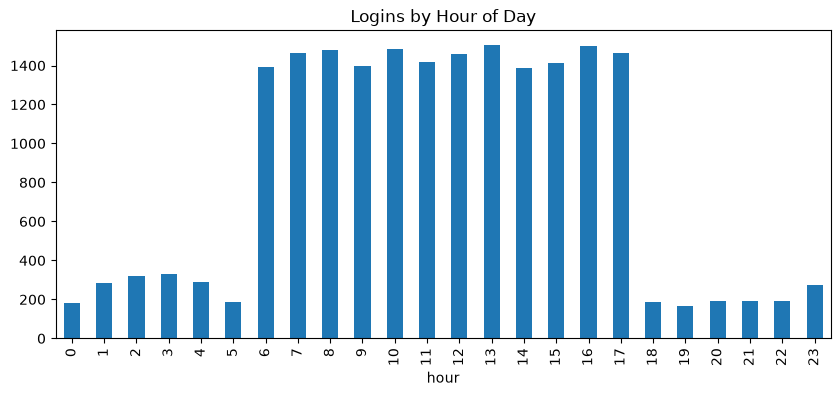

In [5]:
logins["timestamp"] = pd.to_datetime(logins["timestamp"])
logins["hour"] = logins["timestamp"].dt.hour
logins["hour"].value_counts().sort_index().plot(kind="bar", figsize=(10, 4), title="Logins by Hour of Day")
plt.show()

In [6]:
import os
os.makedirs("../../data/processed", exist_ok=True)

for name, df in [("employees", employees), ("access_records", access), ("login_logs", logins),
                  ("audit_findings", findings), ("compliance_controls", controls),
                  ("historical_audits", historical)]:
    df.to_csv(f"../../data/processed/{name}_clean.csv", index=False)

print("Saved cleaned datasets to data/processed/")

Saved cleaned datasets to data/processed/
